Dataset loaded successfully.
Selected file: C:/Users/madha/Downloads/Research Codes/Removed_Few_outliers.csv
Dataset shape: (7386, 15)
Available columns: ['ID_MEASURING_RECORD', 'VOIVODESHIP', 'TOWN', 'MEASURING_POINT_CODE', 'LATITUDE', 'LONGITUDE', 'DATE_MEASUREMENT_START', 'DATE_MEASUREMENT_END', 'PERIOD_AND_TIME_SAMPLING', 'AVG_NOISE_LVL', 'MEU', 'Duration_hours', 'Risk_Level', 'Cumulative_MEU', 'TownCode']

Records available after cleaning: 7362

Risk score distribution:
Risk_Score
1     964
2    3488
3    2910
Name: count, dtype: int64

TRAIN-TEST SPLIT: 80:20
Training records: 5889
Testing records: 1473
MLR Accuracy: 93.21%
MnLR Accuracy: 99.32%
XGB Accuracy: 100.00%
RF Accuracy: 100.00%

TRAIN-TEST SPLIT: 70:30
Training records: 5153
Testing records: 2209
MLR Accuracy: 93.53%
MnLR Accuracy: 99.28%
XGB Accuracy: 100.00%
RF Accuracy: 99.91%

TRAIN-TEST SPLIT: 60:40
Training records: 4417
Testing records: 2945
MLR Accuracy: 93.07%
MnLR Accuracy: 98.68%
XGB Accuracy: 100.00%
RF Accu

,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,93.21,99.32,100.0,100.00
70:30,93.53,99.28,100.0,99.91
60:40,93.07,98.68,100.0,99.80


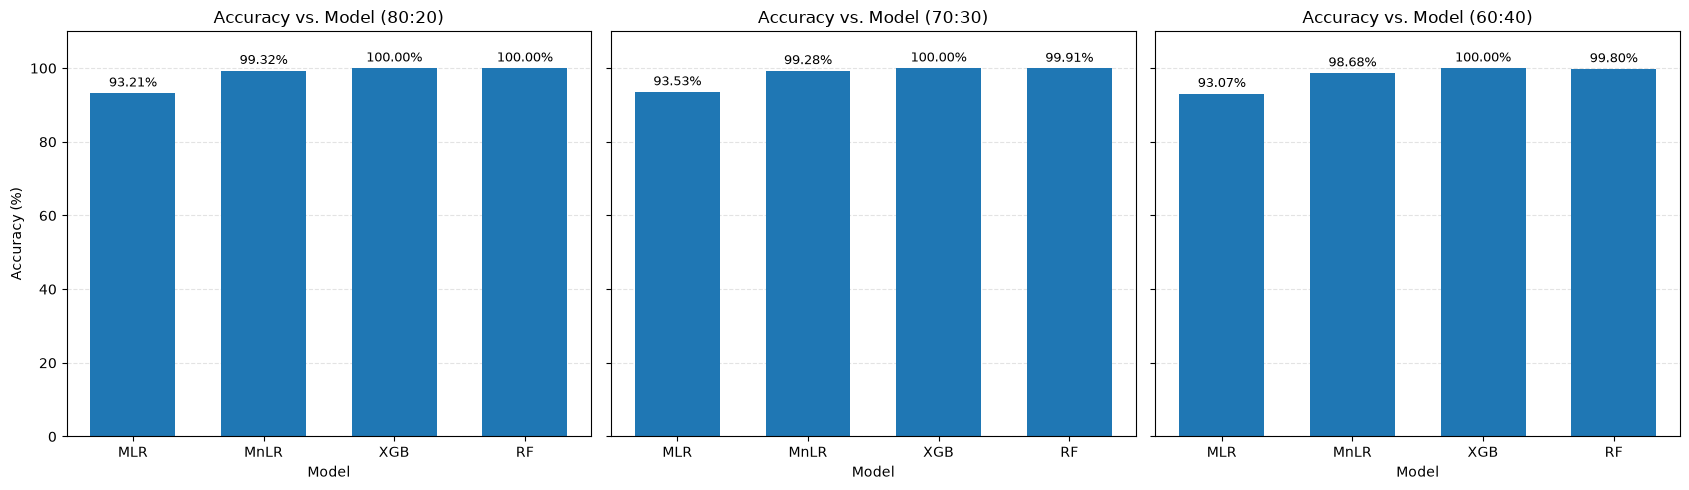

In [3]:
# ================================================================
# ROAD NOISE RISK PREDICTION
# Three Accuracy Graphs: 80:20, 70:30 and 60:40
# Dataset sheet: Road_noise_measurements
# ================================================================

# If needed, run once:
# %pip install pandas openpyxl scikit-learn matplotlib xgboost

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tkinter import Tk, filedialog

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# ================================================================
# 1. SELECT AND LOAD THE EXCEL FILE
# ================================================================

# ================================================================
# 1. SELECT AND LOAD THE EXCEL OR CSV FILE
# ================================================================

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

FILE_PATH = filedialog.askopenfilename(
    title="Select Road Noise Dataset",
    filetypes=[
        ("Supported files", "*.xlsx *.xls *.csv"),
        ("Excel files", "*.xlsx *.xls"),
        ("CSV files", "*.csv")
    ]
)

root.destroy()

if not FILE_PATH:
    raise FileNotFoundError("No file was selected.")

SHEET_NAME = "Road_noise_measurements"

file_extension = Path(FILE_PATH).suffix.lower()

if file_extension == ".csv":
    df = pd.read_csv(FILE_PATH)
elif file_extension in [".xlsx", ".xls"]:
    df = pd.read_excel(
        FILE_PATH,
        sheet_name=SHEET_NAME,
        header=0
    )
else:
    raise ValueError("Unsupported file format.")

df.columns = df.columns.astype(str).str.strip()

print("Dataset loaded successfully.")
print("Selected file:", FILE_PATH)
print("Dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())
# ================================================================
# 2. VALIDATE COLUMNS
# ================================================================

features = [
    "TOWN",
    "LATITUDE",
    "LONGITUDE",
    "Duration_hours",
    "AVG_NOISE_LVL"
]

required_columns = features + ["Risk_Level"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# ================================================================
# 3. CREATE RISK SCORE
# Low = 1, Moderate = 2, High = 3
# ================================================================

risk_mapping = {
    "Low": 1,
    "Moderate": 2,
    "High": 3
}

df["Risk_Level"] = (
    df["Risk_Level"].astype(str).str.strip().str.title()
)

df["Risk_Score"] = df["Risk_Level"].map(risk_mapping)

numeric_features = [
    "LATITUDE",
    "LONGITUDE",
    "Duration_hours",
    "AVG_NOISE_LVL"
]

for col in numeric_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["TOWN"] = df["TOWN"].replace(
    r"^\s*$", np.nan, regex=True
)

# Remove rows without a valid target or town
df = df.dropna(subset=["Risk_Score", "TOWN"]).copy()
df["Risk_Score"] = df["Risk_Score"].astype(int)

X = df[features].copy()
y = df["Risk_Score"].copy()

print("\nRecords available after cleaning:", len(df))
print("\nRisk score distribution:")
print(y.value_counts().sort_index())

if set(y.unique()) != {1, 2, 3}:
    raise ValueError(
        "All three risk scores (1, 2, 3) must be present."
    )

# ================================================================
# 4. PREPROCESSING
# Fit preprocessing separately within each training split.
# ================================================================

def make_preprocessor(scale_numeric=False):

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_transformer = Pipeline(numeric_steps)

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("town", categorical_transformer, ["TOWN"]),
        ("numeric", numeric_transformer, numeric_features)
    ])

# ================================================================
# 5. DEFINE MODELS
# ================================================================

def create_models():

    return {
        "MLR": Pipeline([
            ("preprocessor", make_preprocessor(True)),
            ("model", LinearRegression())
        ]),

        "MnLR": Pipeline([
            ("preprocessor", make_preprocessor(True)),
            ("model", LogisticRegression(
                solver="lbfgs",
                max_iter=2000,
                random_state=42
            ))
        ]),

        "XGB": Pipeline([
            ("preprocessor", make_preprocessor(False)),
            ("model", XGBClassifier(
                objective="multi:softprob",
                num_class=3,
                n_estimators=150,
                max_depth=5,
                learning_rate=0.08,
                subsample=0.9,
                colsample_bytree=0.9,
                eval_metric="mlogloss",
                random_state=42,
                n_jobs=-1
            ))
        ]),

        "RF": Pipeline([
            ("preprocessor", make_preprocessor(False)),
            ("model", RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ])
    }

# ================================================================
# 6. TRAIN AND EVALUATE ALL THREE SPLITS
# ================================================================

splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "60:40": 0.40
}

results = {}

for split_name, test_size in splits.items():

    print(f"\n{'=' * 55}")
    print(f"TRAIN-TEST SPLIT: {split_name}")
    print(f"{'=' * 55}")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    print("Training records:", len(X_train))
    print("Testing records:", len(X_test))

    models = create_models()
    split_results = {}

    for model_name, model in models.items():

        if model_name == "XGB":
            # XGBoost expects labels 0, 1, 2.
            model.fit(X_train, y_train - 1)

            # Restore original labels 1, 2, 3.
            predictions = (
                model.predict(X_test).astype(int) + 1
            )

        else:
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            if model_name == "MLR":
                # Convert regression scores into risk classes.
                predictions = np.clip(
                    np.rint(predictions), 1, 3
                ).astype(int)

        accuracy = accuracy_score(
            y_test, predictions
        ) * 100

        split_results[model_name] = accuracy

        print(f"{model_name} Accuracy: {accuracy:.2f}%")

    results[split_name] = split_results

# ================================================================
# 7. DISPLAY ACCURACY TABLE
# ================================================================

results_df = pd.DataFrame(results).T
results_df.index.name = "Train-Test Split"

print("\nFINAL ACCURACY COMPARISON (%)")
display(results_df.round(2))

# ================================================================
# 8. GENERATE EXACTLY THREE GRAPHS
# ================================================================

model_order = ["MLR", "MnLR", "XGB", "RF"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

for ax, split_name in zip(axes, splits.keys()):

    values = [
        results[split_name][name]
        for name in model_order
    ]

    bars = ax.bar(
        model_order,
        values,
        width=0.65
    )

    ax.set_title(
        f"Accuracy vs. Model ({split_name})",
        fontsize=12
    )

    ax.set_xlabel("Model")
    ax.set_ylim(0, 110)
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.35
    )
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

axes[0].set_ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()

# ================================================================
# END
# ================================================================

F1-Score Comparison (%)


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,93.21,99.32,100.0,100.00
70:30,93.53,99.27,100.0,99.91
60:40,93.08,98.68,100.0,99.80


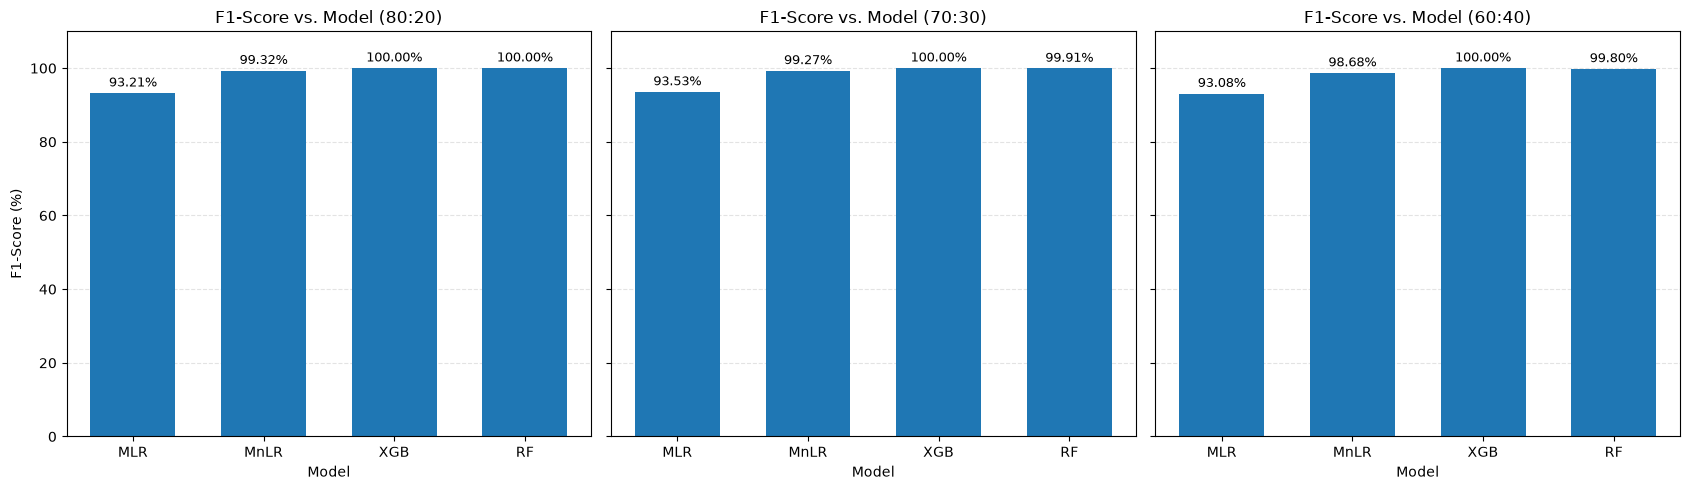

In [4]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Store F1 scores for each split
f1_results = {}

model_order = ["MLR", "MnLR", "XGB", "RF"]

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    models = create_models()
    split_f1 = {}

    for model_name, model in models.items():

        if model_name == "XGB":
            # XGBoost uses class labels 0, 1, 2
            model.fit(X_train, y_train - 1)
            predictions = model.predict(X_test).astype(int) + 1

        else:
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            if model_name == "MLR":
                predictions = np.clip(
                    np.rint(predictions), 1, 3
                ).astype(int)

        # Weighted F1-score for the three risk classes
        score = f1_score(
            y_test,
            predictions,
            labels=[1, 2, 3],
            average="weighted",
            zero_division=0
        ) * 100

        split_f1[model_name] = score

    f1_results[split_name] = split_f1

# Display F1-score results
f1_df = pd.DataFrame(f1_results).T
f1_df.index.name = "Train-Test Split"

print("F1-Score Comparison (%)")
display(f1_df.round(2))

# Generate three F1-score graphs
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

for ax, split_name in zip(axes, splits.keys()):

    values = [
        f1_results[split_name][name]
        for name in model_order
    ]

    bars = ax.bar(
        model_order,
        values,
        width=0.65
    )

    ax.set_title(
        f"F1-Score vs. Model ({split_name})",
        fontsize=12
    )
    ax.set_xlabel("Model")
    ax.set_ylim(0, 110)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

axes[0].set_ylabel("F1-Score (%)")

plt.tight_layout()
plt.show()


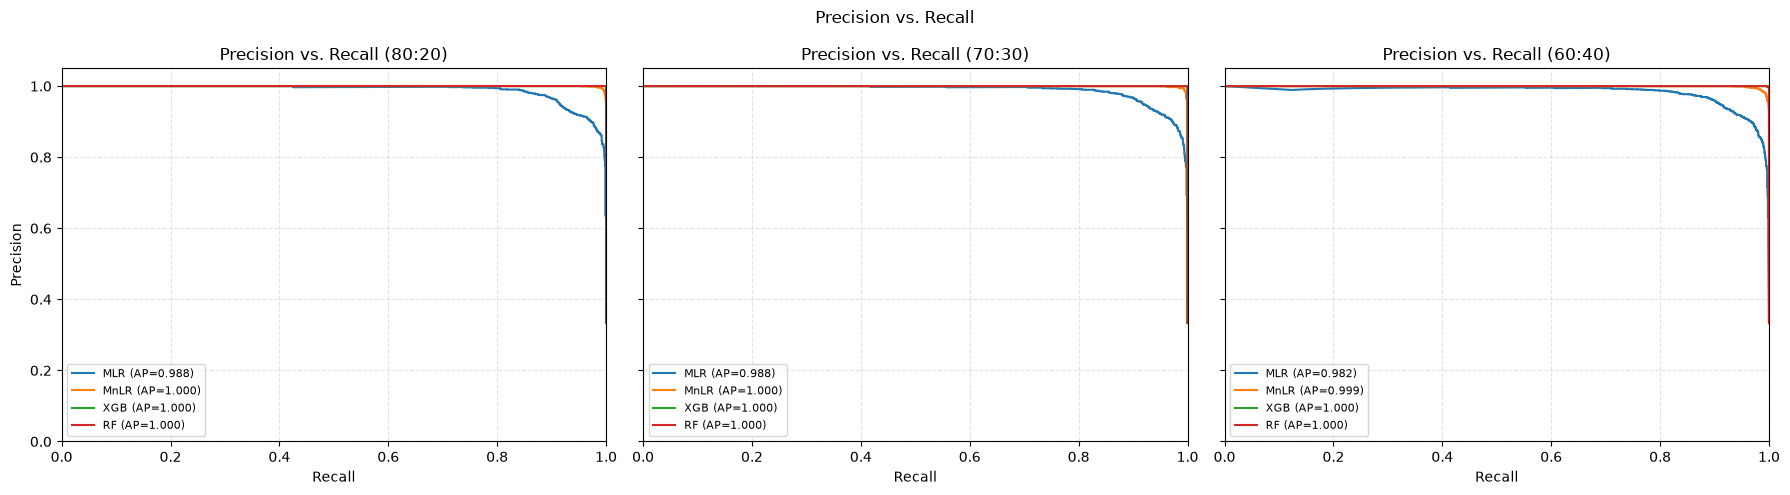

In [5]:
# ================================================================
# PRECISION-RECALL GRAPHS: ONE CURVE PER MODEL
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score

model_order = ["MLR", "MnLR", "XGB", "RF"]
class_labels = [1, 2, 3]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, (split_name, test_size) in zip(axes, splits.items()):

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    models = create_models()
    y_test_binary = label_binarize(y_test, classes=class_labels)

    for model_name in model_order:

        model = models[model_name]

        if model_name == "XGB":
            model.fit(X_train, y_train - 1)
            scores = model.predict_proba(X_test)

        elif model_name == "MLR":
            model.fit(X_train, y_train)
            raw = model.predict(X_test)

            # Convert regression predictions to continuous class scores
            scores = np.column_stack([
                np.clip(1 - np.abs(raw - c), 0, 1)
                for c in class_labels
            ])

            scores = scores / np.maximum(
                scores.sum(axis=1, keepdims=True), 1e-12
            )

        else:
            model.fit(X_train, y_train)
            probabilities = model.predict_proba(X_test)
            fitted_classes = model.named_steps["model"].classes_

            scores = np.column_stack([
                probabilities[:, list(fitted_classes).index(c)]
                for c in class_labels
            ])

        # Micro-average across all three classes
        precision, recall, _ = precision_recall_curve(
            y_test_binary.ravel(),
            scores.ravel()
        )

        ap = average_precision_score(
            y_test_binary,
            scores,
            average="micro"
        )

        ax.plot(
            recall,
            precision,
            linewidth=1.5,
            label=f"{model_name} (AP={ap:.3f})"
        )

    ax.set_title(f"Precision vs. Recall ({split_name})")
    ax.set_xlabel("Recall")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(fontsize=8, loc="lower left")

axes[0].set_ylabel("Precision")

plt.suptitle("Precision vs. Recall")
plt.tight_layout()
plt.show()

In [6]:
splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "60:40": 0.40
}

Calculating ROC curves for 80:20...
Calculating ROC curves for 70:30...
Calculating ROC curves for 60:40...


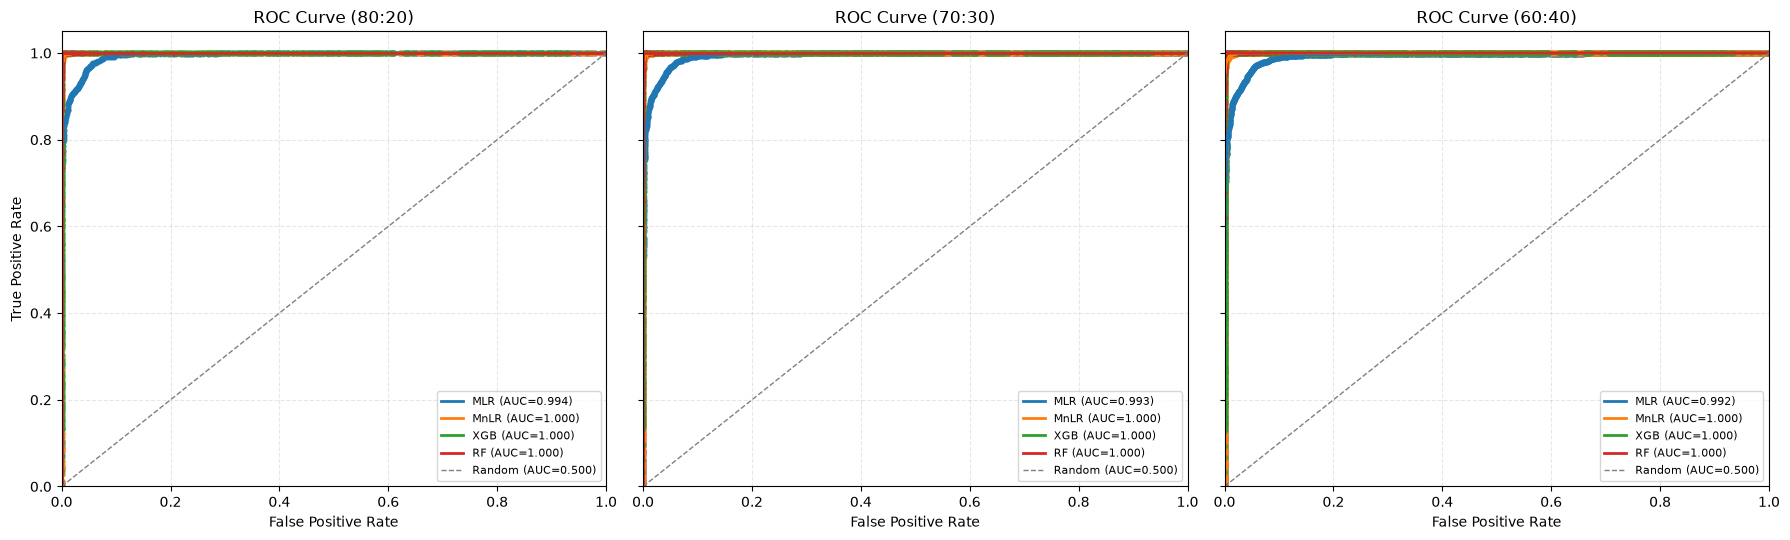

Micro-average ROC-AUC scores:


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,0.9936,0.9999,1.0,1.0
70:30,0.9935,0.9999,1.0,1.0
60:40,0.9917,0.9997,1.0,1.0


In [7]:
# ============================================================
# ROC CURVES FOR FOUR MODELS
# 80:20, 70:30 and 60:40 train-test splits
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

classes = [1, 2, 3]
model_order = ["MLR", "MnLR", "XGB", "RF"]

roc_results = {}

for split_name, test_size in splits.items():

    print(f"Calculating ROC curves for {split_name}...")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    y_test_binary = label_binarize(y_test, classes=classes)
    split_results = {}

    for name, model in create_models().items():

        if name == "XGB":
            model.fit(X_train, y_train - 1)
            raw_scores = model.predict_proba(X_test)
            model_classes = [1, 2, 3]

        elif name == "MLR":
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            # Convert continuous predictions to class-closeness scores
            raw_scores = np.column_stack([
                -np.abs(predictions - cls) for cls in classes
            ])
            model_classes = classes

        else:
            model.fit(X_train, y_train)
            raw_scores = model.predict_proba(X_test)
            model_classes = model.named_steps["model"].classes_

        # Align scores with classes 1, 2, 3
        scores = np.zeros((len(X_test), len(classes)))

        for j, cls in enumerate(model_classes):
            scores[:, int(cls) - 1] = raw_scores[:, j]

        # Micro-average ROC curve
        fpr, tpr, _ = roc_curve(
            y_test_binary.ravel(),
            scores.ravel()
        )

        roc_auc = auc(fpr, tpr)

        split_results[name] = {
            "fpr": fpr,
            "tpr": tpr,
            "auc": roc_auc
        }

    roc_results[split_name] = split_results

# ============================================================
# PLOT THREE ROC GRAPHS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.5),
    sharey=True
)

for ax, split_name in zip(axes, splits.keys()):

    for name in model_order:

        result = roc_results[split_name][name]
        fpr = result["fpr"]
        tpr = result["tpr"]
        model_auc = result["auc"]

        # Mark ROC points and connect them
        ax.scatter(fpr, tpr, s=10, alpha=0.5)
        ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{name} (AUC={model_auc:.3f})"
        )

    # Random-classifier reference
    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        linewidth=1,
        color="gray",
        label="Random (AUC=0.500)"
    )

    ax.set_title(f"ROC Curve ({split_name})")
    ax.set_xlabel("False Positive Rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")

axes[0].set_ylabel("True Positive Rate")

plt.tight_layout()
plt.show()

# ============================================================
# DISPLAY AUC SUMMARY
# ============================================================

auc_table = pd.DataFrame({
    split_name: {
        name: roc_results[split_name][name]["auc"]
        for name in model_order
    }
    for split_name in splits
}).T

auc_table.index.name = "Train-Test Split"

print("Micro-average ROC-AUC scores:")
display(auc_table.round(4))


Evaluating 80:20 split

Evaluating 70:30 split

Evaluating 60:40 split

Mean Accuracy (%) Across Five Random Seeds


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,93.97,99.01,100.0,99.95
70:30,93.79,99.00,100.0,99.95
60:40,93.47,98.61,100.0,99.90



Standard Deviation (%)


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,0.733,0.218,0.0,0.121
70:30,0.614,0.251,0.0,0.050
60:40,0.710,0.197,0.0,0.077



Accuracy for Every Individual Run


,Split,Model,Seed,Accuracy (%)
0,80:20,MLR,42,93.2111
1,80:20,MLR,43,93.6185
2,80:20,MLR,44,94.2295
3,80:20,MLR,45,93.6864
4,80:20,MLR,46,95.1120
5,80:20,MnLR,42,99.3211
6,80:20,MnLR,43,98.7101
7,80:20,MnLR,44,99.0496
8,80:20,MnLR,45,98.9817
9,80:20,MnLR,46,98.9817


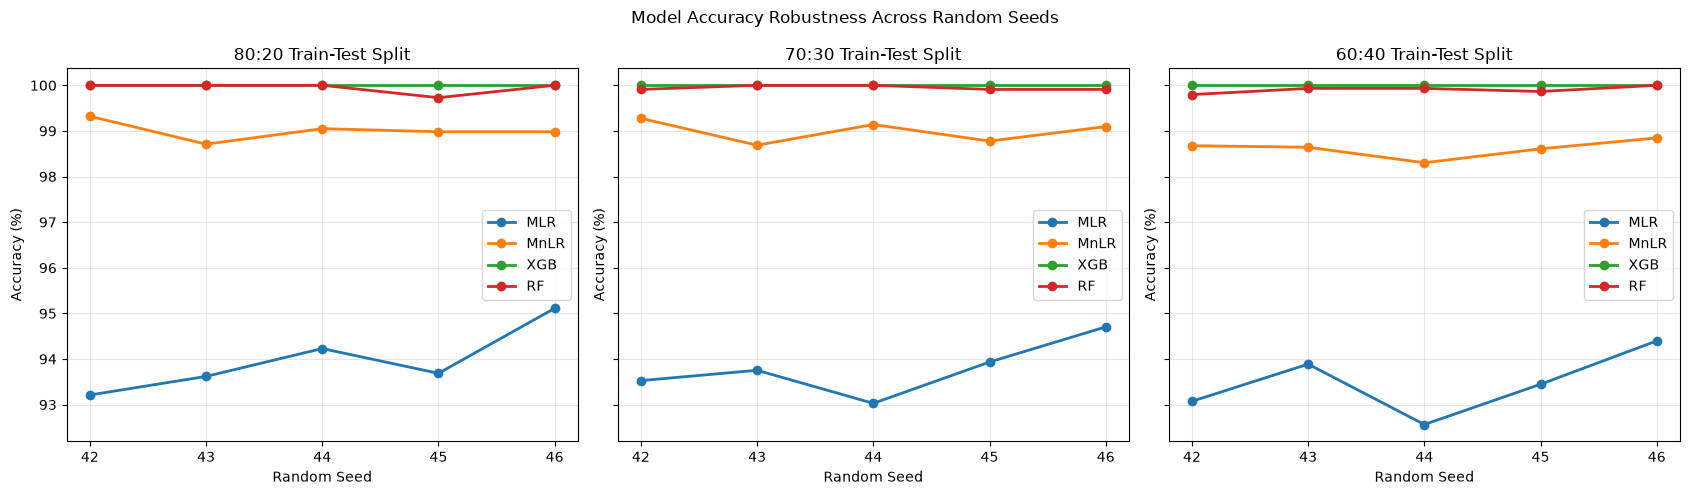

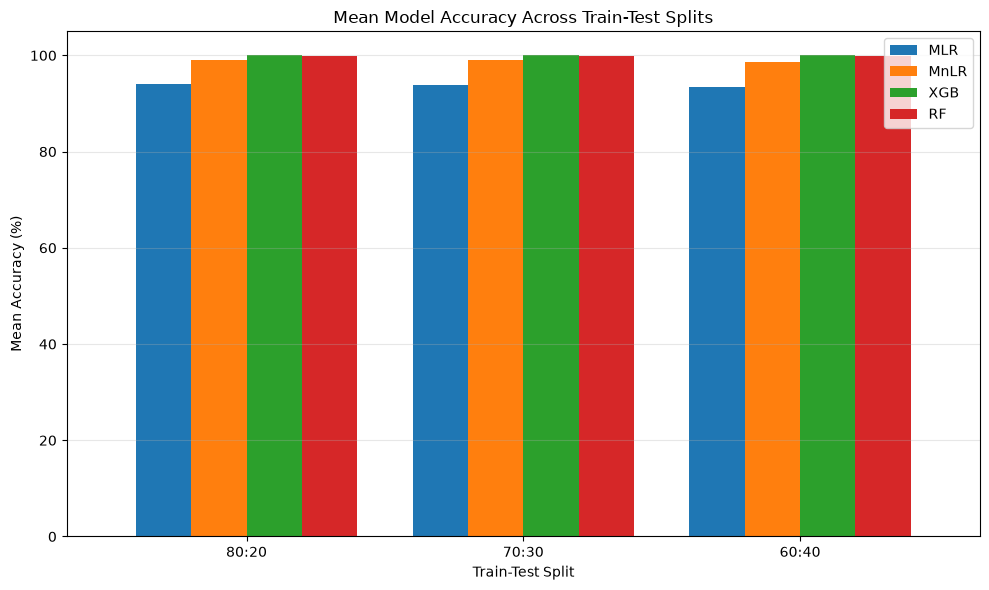

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ==================================================
# 1. CONFIGURATION
# ==================================================

features = [
    "TOWN",
    "LATITUDE",
    "LONGITUDE",
    "Duration_hours",
    "AVG_NOISE_LVL"
]

target = "Risk_Score"

model_order = ["MLR", "MnLR", "XGB", "RF"]

splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "60:40": 0.40
}

random_seeds = [42, 43, 44, 45, 46]

data = df[features + [target]].dropna().copy()

X = data[features]
y = data[target].astype(int)

# Store accuracy for each model, split and seed
robustness_results = {
    split: {model: [] for model in model_order}
    for split in splits
}

# ==================================================
# 2. RUN ROBUSTNESS EXPERIMENT
# ==================================================

for split_name, test_size in splits.items():

    print(f"\nEvaluating {split_name} split")

    for seed in random_seeds:

        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=test_size,
            random_state=seed,
            stratify=y
        )

        models = create_models()

        for model_name in model_order:

            model = models[model_name]

            if model_name == "XGB":
                model.fit(X_train, y_train - 1)
                predictions = model.predict(X_test).astype(int) + 1

            elif model_name == "MLR":
                model.fit(X_train, y_train)
                predictions = np.clip(
                    np.rint(model.predict(X_test)), 1, 3
                ).astype(int)

            else:
                model.fit(X_train, y_train)
                predictions = model.predict(X_test)

            accuracy = accuracy_score(
                y_test, predictions
            ) * 100

            robustness_results[split_name][model_name].append(
                accuracy
            )

# ==================================================
# 3. CALCULATE MEAN ACCURACY AND STANDARD DEVIATION
# ==================================================

mean_results = pd.DataFrame(
    {
        split: {
            model: np.mean(robustness_results[split][model])
            for model in model_order
        }
        for split in splits
    }
).T

std_results = pd.DataFrame(
    {
        split: {
            model: np.std(
                robustness_results[split][model],
                ddof=1
            )
            for model in model_order
        }
        for split in splits
    }
).T

mean_results.index.name = "Train-Test Split"
std_results.index.name = "Train-Test Split"

print("\nMean Accuracy (%) Across Five Random Seeds")
display(mean_results.round(2))

print("\nStandard Deviation (%)")
display(std_results.round(3))

# ==================================================
# 4. INDIVIDUAL MODEL ACCURACY
# ==================================================

rows = []

for split in splits:
    for model in model_order:
        for seed, accuracy in zip(
            random_seeds,
            robustness_results[split][model]
        ):
            rows.append({
                "Split": split,
                "Model": model,
                "Seed": seed,
                "Accuracy (%)": accuracy
            })

individual_results = pd.DataFrame(rows)

print("\nAccuracy for Every Individual Run")
display(individual_results.round(4))

# ==================================================
# 5. ROBUSTNESS GRAPH
# ==================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)

for ax, split in zip(axes, splits):

    for model in model_order:
        ax.plot(
            random_seeds,
            robustness_results[split][model],
            marker="o",
            linewidth=2,
            label=model
        )

    ax.set_title(f"{split} Train-Test Split")
    ax.set_xlabel("Random Seed")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks(random_seeds)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Model Accuracy Robustness Across Random Seeds")
plt.tight_layout()
plt.show()

# ==================================================
# 6. MEAN ACCURACY COMPARISON
# ==================================================

ax = mean_results.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

ax.set_title("Mean Model Accuracy Across Train-Test Splits")
ax.set_xlabel("Train-Test Split")
ax.set_ylabel("Mean Accuracy (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

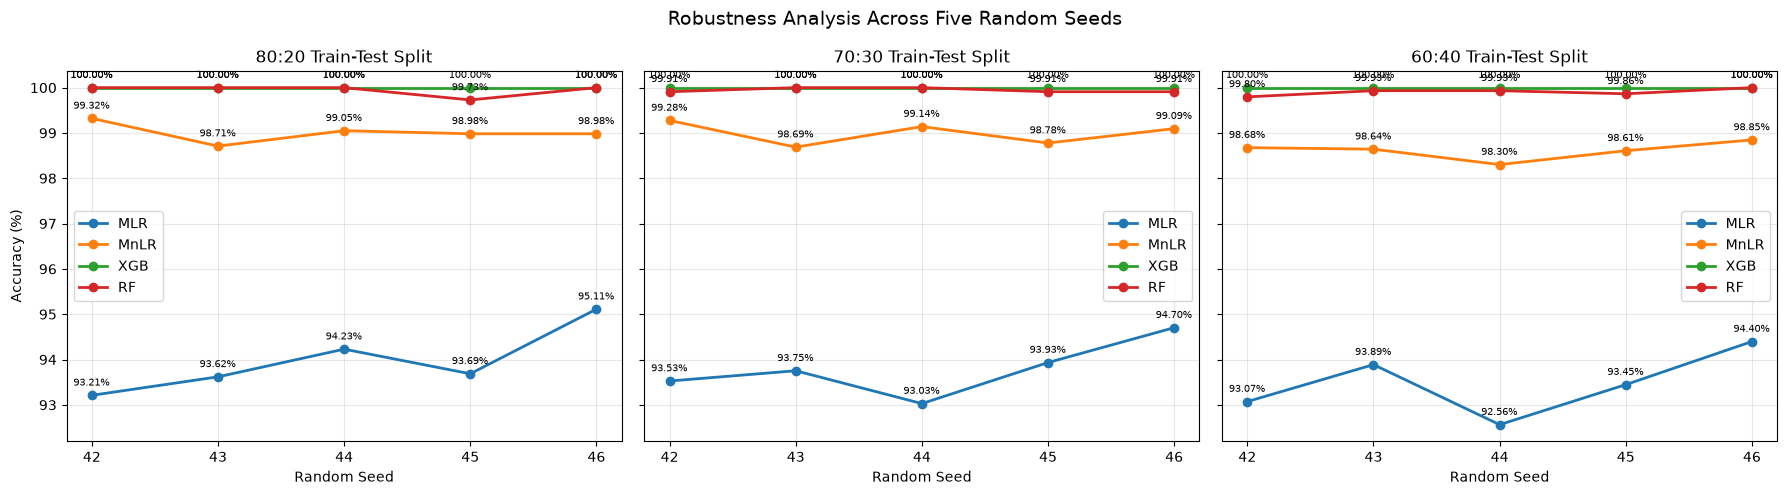

In [9]:
import matplotlib.pyplot as plt

model_order = ["MLR", "MnLR", "XGB", "RF"]
random_seeds = [42, 43, 44, 45, 46]
splits = ["80:20", "70:30", "60:40"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, split in zip(axes, splits):
    for model in model_order:
        accuracies = robustness_results[split][model]

        ax.plot(
            random_seeds,
            accuracies,
            marker="o",
            linewidth=2,
            label=model
        )

        # Display accuracy values beside points
        for seed, accuracy in zip(random_seeds, accuracies):
            ax.annotate(
                f"{accuracy:.2f}%",
                (seed, accuracy),
                textcoords="offset points",
                xytext=(0, 7),
                ha="center",
                fontsize=7
            )

    ax.set_title(f"{split} Train-Test Split")
    ax.set_xlabel("Random Seed")
    ax.set_xticks(random_seeds)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Accuracy (%)")
fig.suptitle(
    "Robustness Analysis Across Five Random Seeds",
    fontsize=14
)

plt.tight_layout()
plt.show()

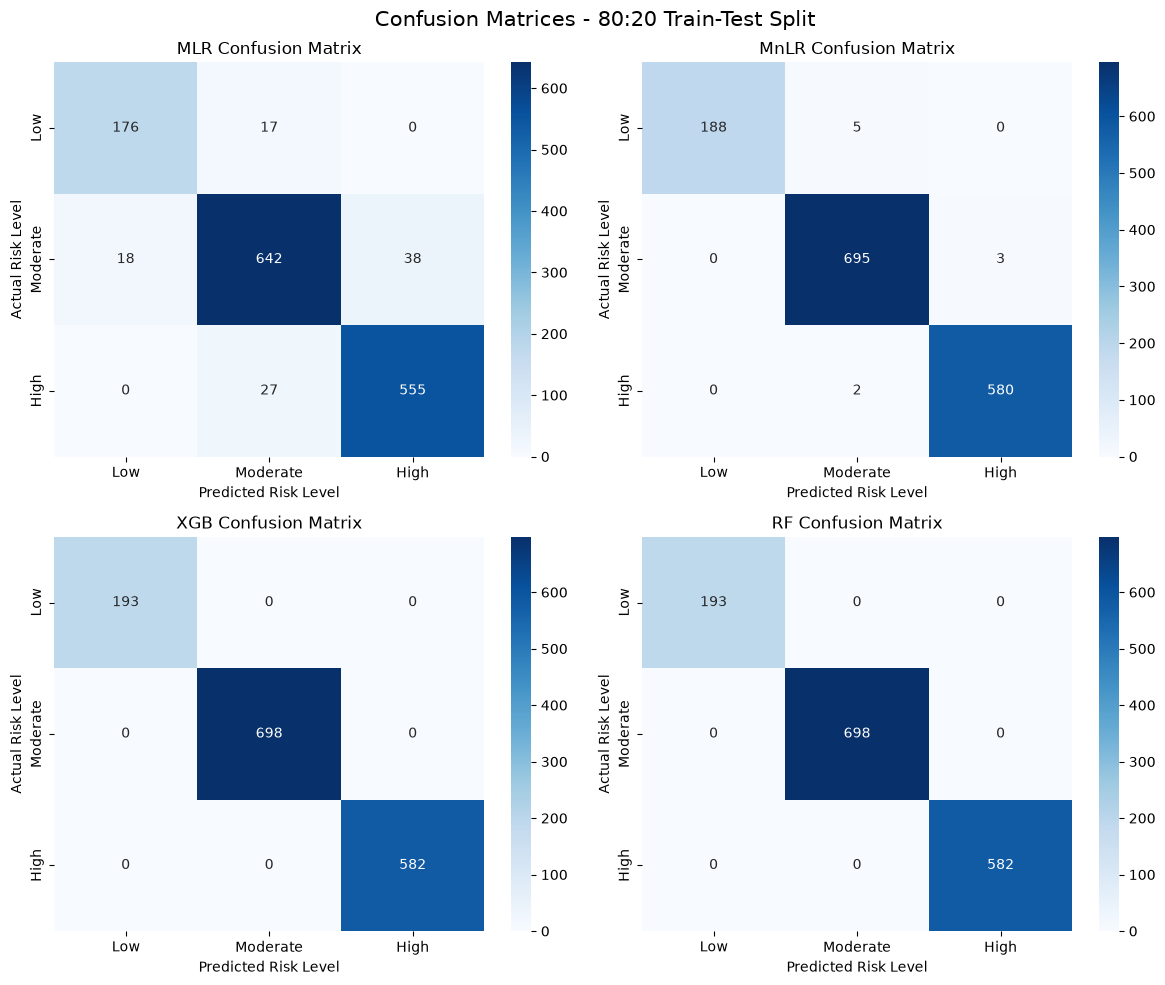

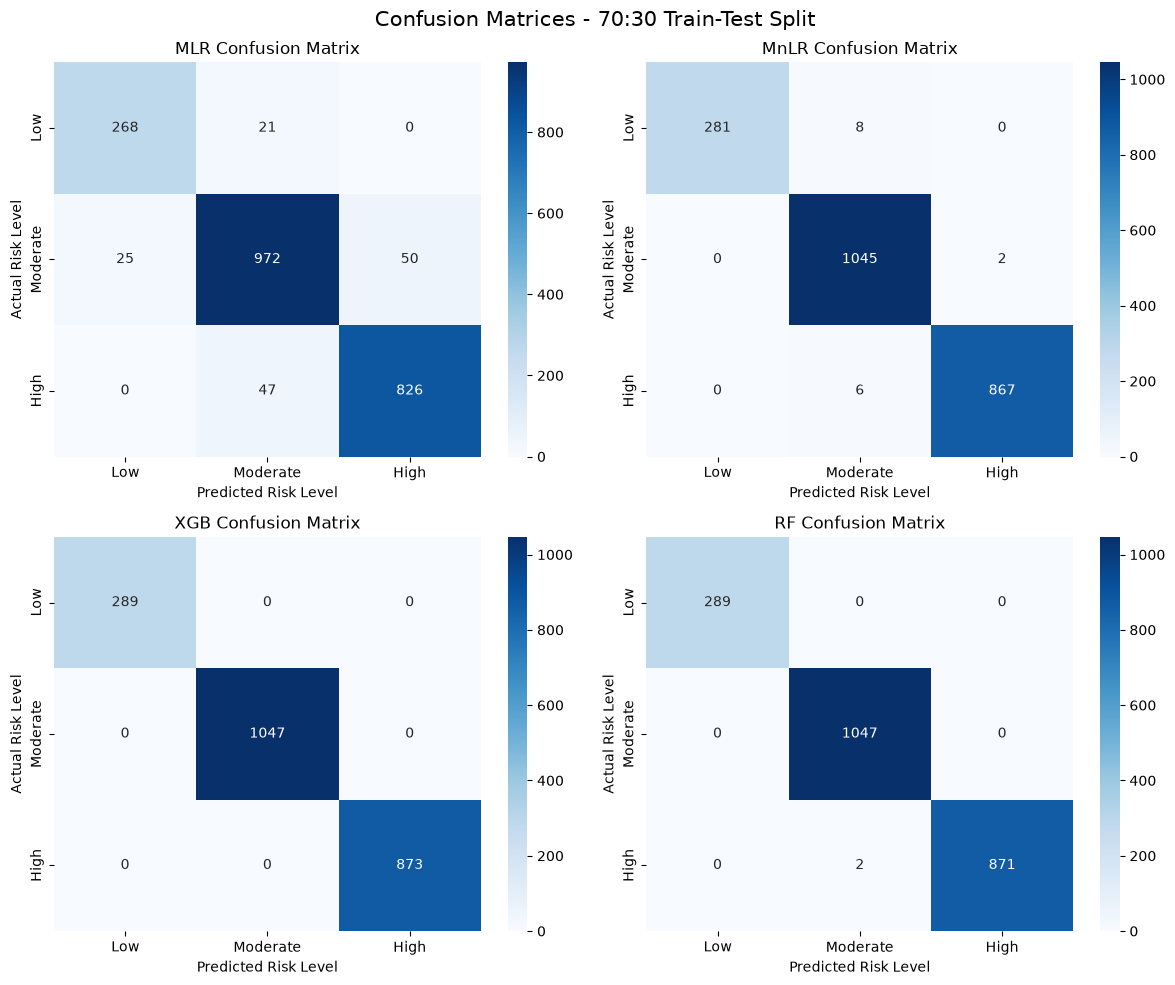

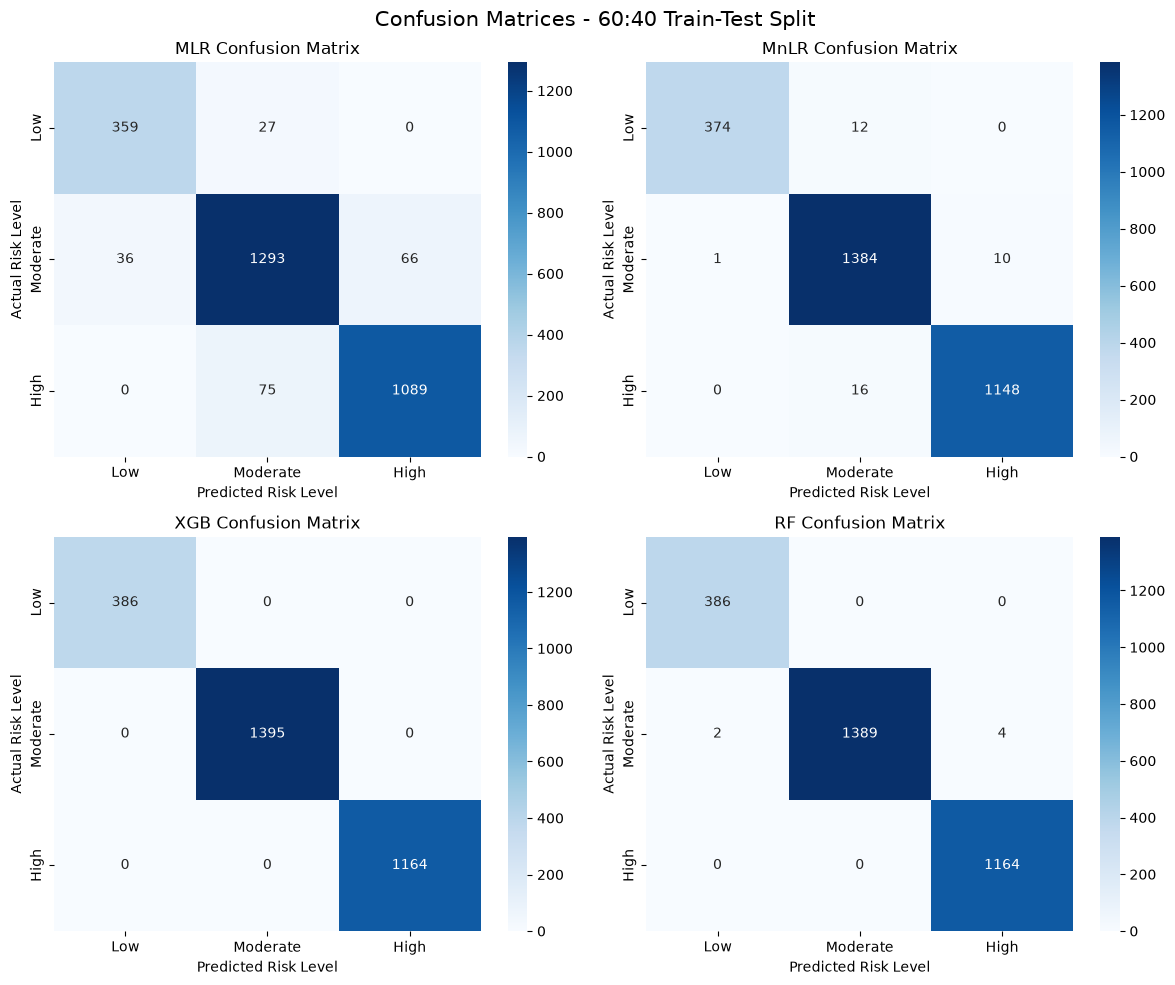

In [10]:
# ================================================================
# CONFUSION MATRIX FOR ALL MODELS AND TRAIN-TEST SPLITS
# ================================================================

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Define splits as a dictionary
splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "60:40": 0.40
}

model_order = ["MLR", "MnLR", "XGB", "RF"]
class_labels = [1, 2, 3]
class_names = ["Low", "Moderate", "High"]

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    models = create_models()

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()

    for ax, model_name in zip(axes, model_order):

        model = models[model_name]

        if model_name == "XGB":
            model.fit(X_train, y_train - 1)
            y_pred = model.predict(X_test).astype(int) + 1

        elif model_name == "MLR":
            model.fit(X_train, y_train)
            y_pred = np.clip(
                np.rint(model.predict(X_test)), 1, 3
            ).astype(int)

        else:
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=class_labels
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names,
            ax=ax
        )

        ax.set_title(f"{model_name} Confusion Matrix")
        ax.set_xlabel("Predicted Risk Level")
        ax.set_ylabel("Actual Risk Level")

    plt.suptitle(
        f"Confusion Matrices - {split_name} Train-Test Split",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

TOP 10 RISKIEST TOWNS - ROAD NOISE ANALYSIS


,Rank,TOWN,Total_Records,Average_Risk_Score,Average_Noise_dB,Average_Duration_Hours,High_Risk_Count,High_Risk_Percentage
0,1,Boczow,4,3.000,72.20,12.00,4,100.00
1,2,Rudnik Szlachecki,4,3.000,70.45,12.00,4,100.00
2,3,Siedliska,4,3.000,69.20,12.00,4,100.00
3,4,Charzewice,4,3.000,68.80,12.00,4,100.00
4,5,Debowa Leka,4,3.000,67.65,12.00,4,100.00
5,6,Wroclaw,1016,2.974,70.76,9.89,990,97.44
6,7,Kaszow,58,2.897,68.07,10.62,52,89.66
7,8,Wschowa,42,2.857,66.31,8.00,36,85.71
8,9,Tuchola,96,2.833,66.72,10.67,80,83.33
9,10,Grudziadz,96,2.792,66.41,10.00,76,79.17


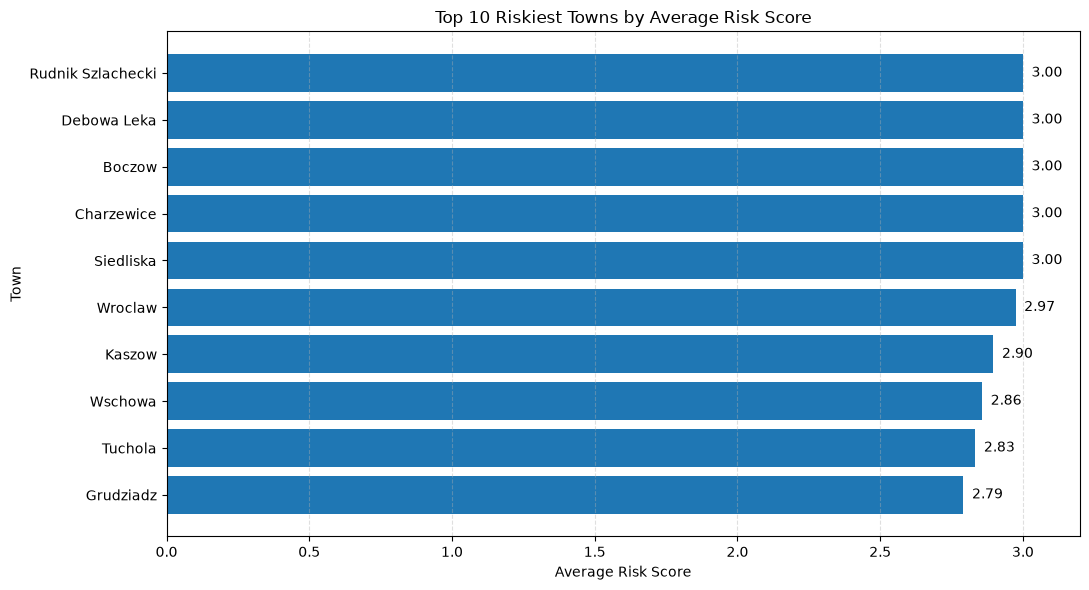

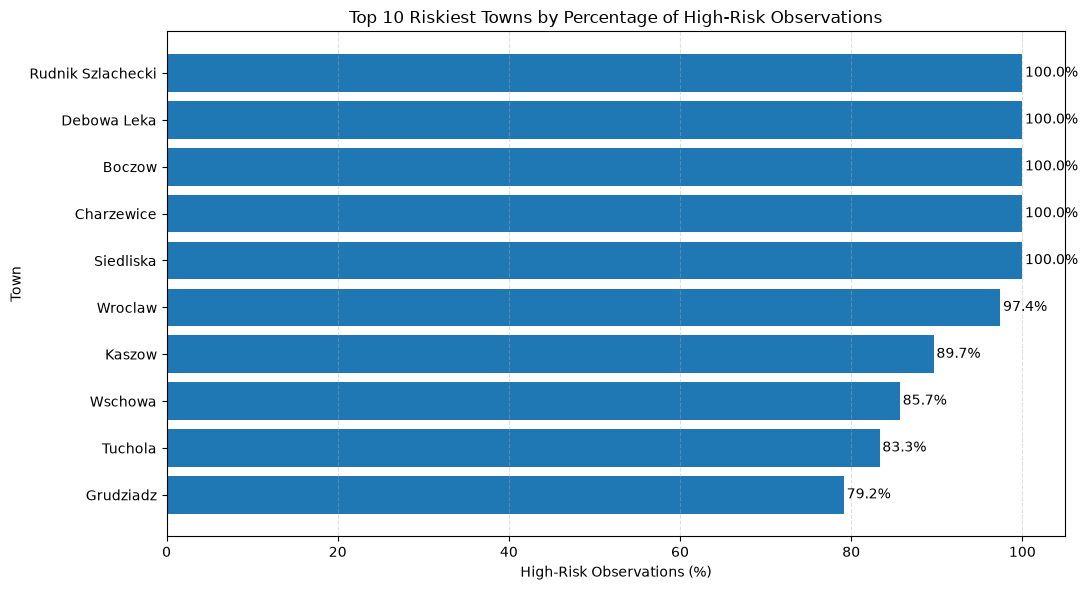

In [11]:
# ================================================================
# TOP 10 RISKIEST TOWNS - ROAD NOISE RISK ANALYSIS
# ================================================================

import pandas as pd
import matplotlib.pyplot as plt

# Use the existing cleaned dataset: df
# Required columns: TOWN, Risk_Score, AVG_NOISE_LVL, Duration_hours

required_columns = [
    "TOWN", "Risk_Score", "AVG_NOISE_LVL", "Duration_hours"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Create a working copy
town_data = df[required_columns].copy()

# Ensure numerical columns are numeric
for col in ["Risk_Score", "AVG_NOISE_LVL", "Duration_hours"]:
    town_data[col] = pd.to_numeric(town_data[col], errors="coerce")

# Remove rows without a town
town_data = town_data.dropna(subset=["TOWN"])
town_data["TOWN"] = town_data["TOWN"].astype(str).str.strip()

town_data = town_data[
    town_data["TOWN"].ne("")
    & town_data["TOWN"].ne("nan")
]

# Calculate town-wise risk statistics
town_risk = town_data.groupby("TOWN").agg(
    Total_Records=("Risk_Score", "count"),
    Average_Risk_Score=("Risk_Score", "mean"),
    Average_Noise_dB=("AVG_NOISE_LVL", "mean"),
    Average_Duration_Hours=("Duration_hours", "mean"),
    High_Risk_Count=("Risk_Score", lambda x: (x == 3).sum())
)

# Calculate percentage of high-risk observations
town_risk["High_Risk_Percentage"] = (
    town_risk["High_Risk_Count"]
    / town_risk["Total_Records"]
    * 100
)

# Keep towns with at least one valid risk observation
town_risk = town_risk[town_risk["Total_Records"] > 0]

# Rank by average risk score, then high-risk percentage,
# then average noise level
top_10_towns = (
    town_risk.sort_values(
        by=[
            "Average_Risk_Score",
            "High_Risk_Percentage",
            "Average_Noise_dB"
        ],
        ascending=False
    )
    .head(10)
    .reset_index()
)

# Add ranking column
top_10_towns.insert(
    0, "Rank", range(1, len(top_10_towns) + 1)
)

# Display results
print("=" * 85)
print("TOP 10 RISKIEST TOWNS - ROAD NOISE ANALYSIS")
print("=" * 85)

display(
    top_10_towns.round({
        "Average_Risk_Score": 3,
        "Average_Noise_dB": 2,
        "Average_Duration_Hours": 2,
        "High_Risk_Percentage": 2
    })
)

# ================================================================
# VISUALIZATION 1: TOP 10 TOWNS BY AVERAGE RISK SCORE
# ================================================================

plot_data = top_10_towns.sort_values(
    "Average_Risk_Score", ascending=True
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    plot_data["TOWN"],
    plot_data["Average_Risk_Score"]
)

plt.xlabel("Average Risk Score")
plt.ylabel("Town")
plt.title("Top 10 Riskiest Towns by Average Risk Score")
plt.xlim(0, 3.2)
plt.grid(axis="x", linestyle="--", alpha=0.4)

for bar in bars:
    plt.text(
        bar.get_width() + 0.03,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center"
    )

plt.tight_layout()
plt.show()

# ================================================================
# VISUALIZATION 2: HIGH-RISK OBSERVATION PERCENTAGE
# ================================================================

plot_data = top_10_towns.sort_values(
    "High_Risk_Percentage", ascending=True
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    plot_data["TOWN"],
    plot_data["High_Risk_Percentage"]
)

plt.xlabel("High-Risk Observations (%)")
plt.ylabel("Town")
plt.title("Top 10 Riskiest Towns by Percentage of High-Risk Observations")
plt.grid(axis="x", linestyle="--", alpha=0.4)

for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

Correlation Matrix:


,LATITUDE,LONGITUDE,Duration_hours,AVG_NOISE_LVL,Risk_Level_Numeric
LATITUDE,1.000,-0.016,-0.030,-0.172,-0.146
LONGITUDE,-0.016,1.000,0.042,-0.232,-0.195
Duration_hours,-0.030,0.042,1.000,0.122,0.117
AVG_NOISE_LVL,-0.172,-0.232,0.122,1.000,0.895
Risk_Level_Numeric,-0.146,-0.195,0.117,0.895,1.000


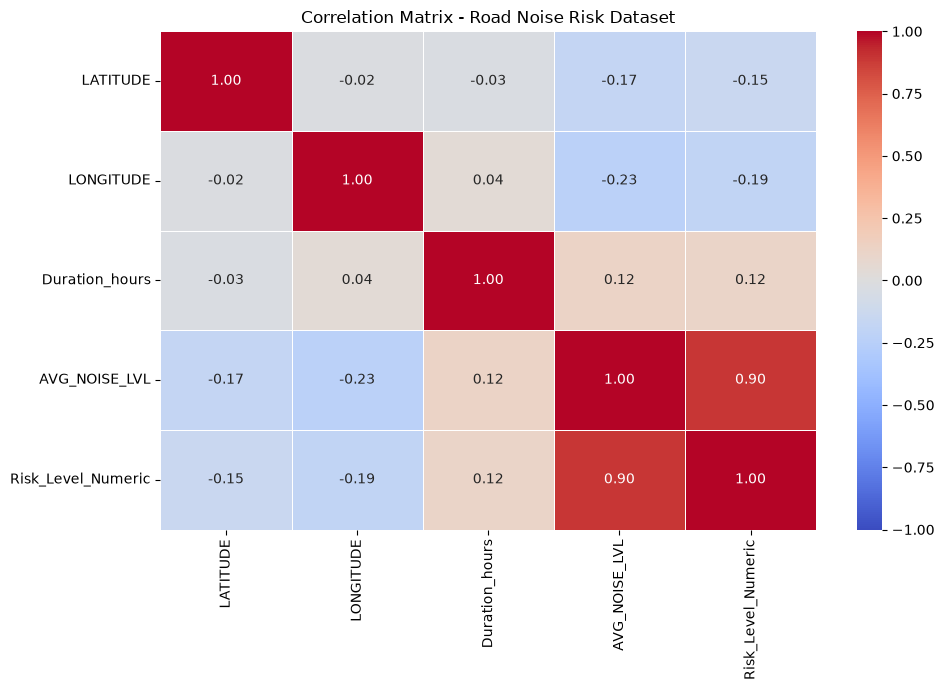

In [16]:
# ============================================================
# CORRELATION MATRIX - ROAD NOISE RISK DATASET
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("Removed_Few_outliers.csv")

# Convert Risk_Level categories to numerical values
risk_mapping = {
    "Low": 1,
    "Moderate": 2,
    "High": 3
}

df["Risk_Level_Numeric"] = (
    df["Risk_Level"]
    .astype(str)
    .str.strip()
    .map(risk_mapping)
)

# Select numerical features and converted target
numeric_columns = [
    "LATITUDE",
    "LONGITUDE",
    "Duration_hours",
    "AVG_NOISE_LVL",
    "Risk_Level_Numeric"
]

# Ensure all selected columns are numeric
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing values in selected columns
corr_data = df[numeric_columns].dropna()

# Calculate Pearson correlation matrix
correlation_matrix = corr_data.corr(method="pearson")

# Display correlation values
print("Correlation Matrix:")
display(correlation_matrix.round(3))

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix - Road Noise Risk Dataset")
plt.tight_layout()
plt.show()



In [19]:
# ================================================================
# COMPLETE AUTOMATIC MODEL EVALUATION TABLES
# Uses existing df, X, y, create_models() from your notebook
# Models: MLR, MnLR, XGB, RF
# Splits: 80:20, 70:30, 60:40
# ================================================================

import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

# -------------------- CONFIGURATION --------------------

model_order = ["MLR", "MnLR", "XGB", "RF"]
class_labels = [1, 2, 3]
class_names = ["Low", "Moderate", "High"]

splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "60:40": 0.40
}

random_seeds = [42, 43, 44, 45, 46]

# Use the existing variables and model definitions
X_eval = X.copy()
y_eval = y.copy()

# -------------------- STORAGE --------------------

metric_rows = []
confusion_rows = []
robustness_rows = []
prediction_rows = []

# ================================================================
# 1. EVALUATE EVERY MODEL ON EVERY TRAIN-TEST SPLIT
# ================================================================

for split_name, test_size in splits.items():

    print(f"\nEvaluating {split_name} split...")

    X_train, X_test, y_train, y_test = train_test_split(
        X_eval,
        y_eval,
        test_size=test_size,
        random_state=42,
        stratify=y_eval
    )

    y_test_binary = label_binarize(
        y_test,
        classes=class_labels
    )

    for model_name, model in create_models().items():

        # Train model using the same procedure as your notebook
        if model_name == "XGB":
            model.fit(X_train, y_train - 1)
            y_pred = model.predict(X_test).astype(int) + 1

            # XGBoost probability columns correspond to classes 0, 1, 2
            y_score = model.predict_proba(X_test)

        elif model_name == "MLR":
            model.fit(X_train, y_train)

            raw_predictions = model.predict(X_test)

            y_pred = np.clip(
                np.rint(raw_predictions), 1, 3
            ).astype(int)

            # Convert regression predictions into class-closeness scores
            y_score = np.column_stack([
                np.clip(
                    1 - np.abs(raw_predictions - cls), 0, 1
                )
                for cls in class_labels
            ])

            # Normalize scores for probability-like class comparisons
            y_score = y_score / np.maximum(
                y_score.sum(axis=1, keepdims=True), 1e-12
            )

        else:
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test).astype(int)

            probabilities = model.predict_proba(X_test)
            fitted_classes = model.named_steps["model"].classes_

            # Align probability columns to classes 1, 2, 3
            y_score = np.zeros(
                (len(X_test), len(class_labels))
            )

            for j, cls in enumerate(fitted_classes):
                if int(cls) in class_labels:
                    y_score[:, int(cls) - 1] = probabilities[:, j]

        # ---------------- CLASSIFICATION METRICS ----------------

        accuracy = accuracy_score(y_test, y_pred) * 100

        balanced_acc = (
            balanced_accuracy_score(y_test, y_pred) * 100
        )

        precision = precision_score(
            y_test, y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0
        ) * 100

        recall = recall_score(
            y_test, y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0
        ) * 100

        weighted_f1 = f1_score(
            y_test, y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0
        ) * 100

        macro_f1 = f1_score(
            y_test, y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0
        ) * 100

        # ---------------- ROC-AUC AND AVERAGE PRECISION ----------------

        try:
            roc_auc = roc_auc_score(
                y_test_binary,
                y_score,
                average="micro"
            )
        except ValueError:
            roc_auc = np.nan

        try:
            avg_precision = average_precision_score(
                y_test_binary,
                y_score,
                average="micro"
            )
        except ValueError:
            avg_precision = np.nan

        metric_rows.append({
            "Train-Test Split": split_name,
            "Model": model_name,
            "Accuracy (%)": accuracy,
            "Balanced Accuracy (%)": balanced_acc,
            "Weighted Precision (%)": precision,
            "Weighted Recall (%)": recall,
            "Weighted F1 (%)": weighted_f1,
            "Macro F1 (%)": macro_f1,
            "Micro ROC-AUC": roc_auc,
            "Micro Average Precision": avg_precision
        })

        # ---------------- CONFUSION MATRIX TABLE ----------------

        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=class_labels
        )

        for i, actual_class in enumerate(class_names):
            for j, predicted_class in enumerate(class_names):

                confusion_rows.append({
                    "Train-Test Split": split_name,
                    "Model": model_name,
                    "Actual Class": actual_class,
                    "Predicted Class": predicted_class,
                    "Count": cm[i, j]
                })

        # ---------------- SAVE PREDICTIONS ----------------

        for actual, predicted in zip(y_test, y_pred):
            prediction_rows.append({
                "Train-Test Split": split_name,
                "Model": model_name,
                "Actual Risk Score": int(actual),
                "Predicted Risk Score": int(predicted)
            })


# ================================================================
# 2. DISPLAY ALL METRIC TABLES
# ================================================================

metrics_df = pd.DataFrame(metric_rows)

print("\n" + "=" * 90)
print("TABLE 1: ALL MODEL PERFORMANCE METRICS")
print("=" * 90)

display(
    metrics_df.sort_values(
        ["Train-Test Split", "Model"]
    ).round(4)
)

# Individual comparison tables
metric_columns = [
    "Accuracy (%)",
    "Balanced Accuracy (%)",
    "Weighted Precision (%)",
    "Weighted Recall (%)",
    "Weighted F1 (%)",
    "Macro F1 (%)",
    "Micro ROC-AUC",
    "Micro Average Precision"
]

for metric in metric_columns:

    print(f"\n{'=' * 75}")
    print(f"TABLE: {metric} COMPARISON")
    print("=" * 75)

    table = metrics_df.pivot(
        index="Train-Test Split",
        columns="Model",
        values=metric
    )

    table = table.reindex(
        index=list(splits.keys()),
        columns=model_order
    )

    display(table.round(4))


# ================================================================
# 3. CONFUSION MATRIX COUNTS FOR EVERY MODEL AND SPLIT
# ================================================================

confusion_df = pd.DataFrame(confusion_rows)

print("\n" + "=" * 90)
print("TABLE: CONFUSION MATRIX COUNTS FOR ALL MODELS AND SPLITS")
print("=" * 90)

display(confusion_df)

# Also display each confusion matrix as a separate table
for split_name in splits:

    for model_name in model_order:

        subset = confusion_df[
            (confusion_df["Train-Test Split"] == split_name) &
            (confusion_df["Model"] == model_name)
        ]

        matrix_table = subset.pivot(
            index="Actual Class",
            columns="Predicted Class",
            values="Count"
        )

        matrix_table = matrix_table.reindex(
            index=class_names,
            columns=class_names
        )

        print(f"\nConfusion Matrix: {model_name} | {split_name}")
        display(matrix_table)


# ================================================================
# 4. ROBUSTNESS ANALYSIS ACROSS FIVE RANDOM SEEDS
# ================================================================

for split_name, test_size in splits.items():

    for seed in random_seeds:

        X_train, X_test, y_train, y_test = train_test_split(
            X_eval,
            y_eval,
            test_size=test_size,
            random_state=seed,
            stratify=y_eval
        )

        for model_name, model in create_models().items():

            if model_name == "XGB":
                model.fit(X_train, y_train - 1)
                y_pred = model.predict(X_test).astype(int) + 1

            elif model_name == "MLR":
                model.fit(X_train, y_train)

                y_pred = np.clip(
                    np.rint(model.predict(X_test)), 1, 3
                ).astype(int)

            else:
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test).astype(int)

            acc = accuracy_score(y_test, y_pred) * 100

            robustness_rows.append({
                "Train-Test Split": split_name,
                "Model": model_name,
                "Random Seed": seed,
                "Accuracy (%)": acc
            })


robustness_df = pd.DataFrame(robustness_rows)

print("\n" + "=" * 90)
print("TABLE: ACCURACY FOR EVERY RANDOM SEED")
print("=" * 90)

display(
    robustness_df.sort_values(
        ["Train-Test Split", "Model", "Random Seed"]
    ).round(4)
)

# Mean and standard deviation of accuracy
robustness_summary = (
    robustness_df
    .groupby(["Train-Test Split", "Model"])["Accuracy (%)"]
    .agg(
        Mean_Accuracy="mean",
        Std_Deviation=lambda values: values.std(ddof=1),
        Minimum="min",
        Maximum="max"
    )
    .reset_index()
)

print("\n" + "=" * 90)
print("TABLE: ROBUSTNESS SUMMARY")
print("=" * 90)

display(robustness_summary.round(4))


# ================================================================
# 5. CREATE ONE COMBINED LONG-FORM RESULTS TABLE
# ================================================================

print("\n" + "=" * 90)
print("TABLE: COMBINED MODEL RESULTS")
print("=" * 90)

display(
    metrics_df.sort_values(
        ["Train-Test Split", "Model"]
    ).reset_index(drop=True).round(4)
)


# ================================================================
# 6. OPTIONAL: EXPORT ALL GENERATED TABLES TO EXCEL
# ================================================================

with pd.ExcelWriter("Automatically_Calculated_Model_Results.xlsx") as writer:

    metrics_df.to_excel(
        writer, sheet_name="All Metrics", index=False
    )

    confusion_df.to_excel(
        writer, sheet_name="Confusion Matrices", index=False
    )

    robustness_df.to_excel(
        writer, sheet_name="Robustness Runs", index=False
    )

    robustness_summary.to_excel(
        writer, sheet_name="Robustness Summary", index=False
    )

    for metric in metric_columns:

        table = metrics_df.pivot(
            index="Train-Test Split",
            columns="Model",
            values=metric
        )

        table = table.reindex(
            index=list(splits.keys()),
            columns=model_order
        )

        sheet_name = metric.replace("%", "Pct").replace(" ", "_")[:31]

        table.to_excel(writer, sheet_name=sheet_name)

print("\nAll tables have been calculated from model predictions.")
print("Excel file created: Automatically_Calculated_Model_Results.xlsx")


Evaluating 80:20 split...

Evaluating 70:30 split...

Evaluating 60:40 split...

TABLE 1: ALL MODEL PERFORMANCE METRICS


,Train-Test Split,Model,Accuracy (%),Balanced Accuracy (%),Weighted Precision (%),Weighted Recall (%),Weighted F1 (%),Macro F1 (%),Micro ROC-AUC,Micro Average Precision
8,60:40,MLR,93.0730,93.0834,93.0834,93.0730,93.0760,92.8471,0.9916,0.9818
9,60:40,MnLR,98.6757,98.2427,98.6844,98.6757,98.6754,98.5942,0.9997,0.9994
11,60:40,RF,99.7963,99.8566,99.7971,99.7963,99.7962,99.7849,1.0000,1.0000
10,60:40,XGB,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,1.0000,1.0000
4,70:30,MLR,93.5265,93.3955,93.5290,93.5265,93.5265,93.2328,0.9938,0.9880
5,70:30,MnLR,99.2757,98.7845,99.2825,99.2757,99.2748,99.1258,0.9999,0.9997
7,70:30,RF,99.9095,99.9236,99.9096,99.9095,99.9095,99.9300,1.0000,1.0000
6,70:30,XGB,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,1.0000,1.0000
0,80:20,MLR,93.2111,92.8432,93.2130,93.2111,93.2054,92.7329,0.9940,0.9883
1,80:20,MnLR,99.3211,98.8786,99.3242,99.3211,99.3200,99.1814,0.9999,0.9998



TABLE: Accuracy (%) COMPARISON


Model,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,93.2111,99.3211,100.0,100.0000
70:30,93.5265,99.2757,100.0,99.9095
60:40,93.0730,98.6757,100.0,99.7963



TABLE: Balanced Accuracy (%) COMPARISON


...


TABLE: ROBUSTNESS SUMMARY


,Train-Test Split,Model,Mean_Accuracy,Std_Deviation,Minimum,Maximum
0,60:40,MLR,93.4737,0.7096,92.5637,94.3973
1,60:40,MnLR,98.6146,0.1971,98.3022,98.8455
2,60:40,RF,99.9049,0.0774,99.7963,100.0000
3,60:40,XGB,100.0000,0.0000,100.0000,100.0000
4,70:30,MLR,93.7890,0.6136,93.0285,94.7035
5,70:30,MnLR,98.9950,0.2508,98.6872,99.2757
6,70:30,RF,99.9457,0.0496,99.9095,100.0000
7,70:30,XGB,100.0000,0.0000,100.0000,100.0000
8,80:20,MLR,93.9715,0.7334,93.2111,95.1120
9,80:20,MnLR,99.0088,0.2179,98.7101,99.3211



TABLE: COMBINED MODEL RESULTS


,Train-Test Split,Model,Accuracy (%),Balanced Accuracy (%),Weighted Precision (%),Weighted Recall (%),Weighted F1 (%),Macro F1 (%),Micro ROC-AUC,Micro Average Precision
0,60:40,MLR,93.0730,93.0834,93.0834,93.0730,93.0760,92.8471,0.9916,0.9818
1,60:40,MnLR,98.6757,98.2427,98.6844,98.6757,98.6754,98.5942,0.9997,0.9994
2,60:40,RF,99.7963,99.8566,99.7971,99.7963,99.7962,99.7849,1.0000,1.0000
3,60:40,XGB,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,1.0000,1.0000
4,70:30,MLR,93.5265,93.3955,93.5290,93.5265,93.5265,93.2328,0.9938,0.9880
5,70:30,MnLR,99.2757,98.7845,99.2825,99.2757,99.2748,99.1258,0.9999,0.9997
6,70:30,RF,99.9095,99.9236,99.9096,99.9095,99.9095,99.9300,1.0000,1.0000
7,70:30,XGB,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,1.0000,1.0000
8,80:20,MLR,93.2111,92.8432,93.2130,93.2111,93.2054,92.7329,0.9940,0.9883
9,80:20,MnLR,99.3211,98.8786,99.3242,99.3211,99.3200,99.1814,0.9999,0.9998



All tables have been calculated from model predictions.
Excel file created: Automatically_Calculated_Model_Results.xlsx
